### **Autores: Brian Bedoya, Daniel Moraleda, Victor Pastor, David Santiago.**

## **Parte 2**

Crea un morphing entre dos imágenes de las caras de dos de los miembros del grupo 1. Necesitaréis considerar muchos detalles que no hemos tratado en clase, porque en pizarra era imposible hacer todos estos cálculos.

- **Entradas y salidas**: ¿Qué formatos, tamaños y tipos de datos espera el script que creéis?
- **Preprocesamiento**: ¿Qué pasos de preprocesado se aplican antes del morphing y por qué ese orden es importante?
- **Algoritmo principal**: ¿Qué método concreto usaréis y por qué se eligió? (Recomendación: Informáos sobre el algortimo de Sinkhorn).
- **Parámetros y decisiones de diseño**: ¿Qué parámetros controlan el resultado (según lo que programéis pueden ser algunos de nº de frames/interpolación, regularización, kernel de suavizado, umbrales) y cómo afectan al resultado final? ¿Cómo se seleccionaron sus valores por defecto?

---
---

### **_1. Introducción: Morphing_**

El **morphing** entre dos imágenes es un problema fundamental en visión computacional que busca generar una transición suave y visualmente coherente entre dos distribuciones. A diferencia de la interpolación lineal clásica, que simplemente mezcla los valores de píxeles mediante $I_t = (1-t)I_0 + tI_1$, el morphing basado en **Transporte Óptimo** preserva la coherencia geométrica haciendo que las estructuras visuales parezcan desplazarse físicamente en el espacio.

**Fundamento Matemático:** 
El teorema de Brenier establece que, bajo condiciones de convexidad, existe un mapa de transporte óptimo que minimiza el coste cuadrático de mover masa entre dos distribuciones de probabilidad $\mu_0$ y $\mu_1$, satisfaciendo $T\#\mu_0 = \mu_1$ (donde $\#$ denota la imagen de medida o *pushforward*). 

Estamos resolviendo el problema de Kantorovich. Buscamos una medida de transporte $\gamma$ en el espacio producto $X \times X$ cuyas marginales coincidan con las imágenes de entrada $\mu$ y $\nu$. Al discretizar las imágenes en una rejilla de píxeles, la integral teórica de Kantorovich $\int c(x,y)d\gamma(x,y)$ se reduce exactamente a la suma lineal finita que resuelve nuestro algoritmo, sirviendo como aproximación numérica del fenómeno continuo.

Este mapa define una **geodésica** en el espacio de Wasserstein mediante la interpolación:

$$ \mu_t = ((1-t)Id + tT)\#\mu_0, \quad t \in [0,1] $$

**Interpretación de la Fórmula:**
*   $\boldsymbol{\mu_0}$: Distribución de la imagen inicial (Cara A).
*   $\boldsymbol{T}$: Mapa de transporte que mapea el destino final de cada píxel.
*   $\boldsymbol{Id}$: Identidad (posición original), asegurando que si $t=0$, no hay movimiento.
*   $\boldsymbol{t}$: Tiempo o parámetro de interpolación ($0 \to 1$). Si $t=0.5$, estamos a mitad de camino.
*   $\boldsymbol{(1-t)Id + tT}$: Promedio ponderado de la posición. En $t=0.5$, cada partícula está al 50% entre su origen y su destino.
*   $\boldsymbol{\#}$: Operador *pushforward*, indicando que colocamos la masa de $\mu_0$ en las nuevas posiciones calculadas.

**Intuición Visual:**
Una geodésica es el camino más recto y corto posible en un espacio curvo (e.g., ruta de vuelo Madrid-Sidney). En el espacio de Wasserstein, la distancia se mide por el coste de *mover* píxeles. La geodésica es la ruta que transforma la Cara A en la Cara B gastando la mínima energía cinética posible. Si t = 0.5, estaremos un 50% en el lugar original y un 50% en el destino.

Este enfoque garantiza tres propiedades clave:
1.  **Conservación de Masa:** No aparece ni desaparece información arbitrariamente ("evaporación" vs movimiento).
2.  **Movimiento Mínimo:** La distorsión geométrica es la mínima posible según la métrica $W_2$.
3.  **Transición Natural:** Los rasgos faciales fluyen elásticamente de un rostro a otro.

### **_2. Entradas y Salidas_**

**1. Entradas**
*   **Imágenes:** Dos imágenes con rostros frontales.
*   **Formato:** Carga como `uint8` (0-255) $\to$ Conversión a `float64` (precisión numérica) $\to$ Normalización a distribución de probabilidad. Si no usasemos float, al normalizar la imagen los valores se redondearían a 0 (negro).
*   **Resolución:**
    *   La complejidad computacional del transporte óptimo es comúnmente $O(n^3)$ o $O(n^2 \log n)$.
    *   Utilizaremos una resolución de **$128 \times 128$** ($16,384$ píxeles) como baseline para reducir la complejidad al máximo, aunque será un parámetro ajustable según como funcione.
*   **Color:** Convertimos a escala de grises para resolver un único problema de OT en lugar de tres (R, G, B), priorizando la calidad geométrica.

**2. Salidas**
*   Secuencia de imágenes intermedias $\{\mu_t\}$ para $t \in \{0, 1/N, 2/N, ..., 1\}$.
*   Visualización estática (Grid de estados) o dinámica (GIF) de la transformación geodésica.

In [126]:
!pip install numpy opencv-python imageio matplotlib scipy

In [127]:
import numpy as np
import cv2
import imageio
import matplotlib.pyplot as plt
from scipy.ndimage import convolve1d, gaussian_filter

# Configuración de visualización
%matplotlib inline

### **_3. Preprocesamiento_**

Para garantizar la convergencia y calidad del algoritmo, aplicamos el siguiente pipeline:

1.  **Detección y Recorte (Face Crop):**
    *   Usamos `OpenCV Haar Cascade`.
    *   Alineamos la región de interés para evitar el desperdicio de tiempo deformando el fondo o el cuello y para intentar encuadrar y hacer el menor ghosting posible. Margen del 30% adicional.

2.  **Conversión a Escala de Grises:**
    *   Transformación lineal `COLOR_BGR2GRAY`. Reduce la dimensionalidad del problema de $3n$ a $n$.

3.  **Regularización Numérica:**
    *   Suma de $\epsilon = 1e^{-8}$ a todos los píxeles. Evita divisiones por cero (`NaN`) o logaritmos de cero ($-\infty$) durante las iteraciones de Sinkhorn.

4.  **Normalización de Masa:**
    *   Dividimos cada píxel por la suma total de intensidades: $\sum I_{ij} = 1$.
    *   Convertimos la imagen en una **distribución de probabilidad discreta**. Esto es requisito indispensable del Teorema de Kantorovich (la masa total a mover debe ser igual a la masa total recibida). Si no normalizásemos no podríamos transportar los píxeles de una imagen a otra porque no tendríamos la misma masa total. 
Por el `teorema de Kantorovich`, debemos minimizar el coste del transporte de tal forma que todos los píxeles de A se utilizen para llegar a todos los píxeles de B (principio de conservación de masa de la introducción). Al normalizar, deja de importar si la foto inicial era clara (píxeles más cercanos a 255, por lo que la suma total será mayor) u oscura (píxeles más cercanos a 0) porque la suma total en ambos casos será 1.

In [128]:
# Clasificador de rostros pre-entrenado
try:
    FACE_CASCADE = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_frontalface_default.xml")
except:
    pass

def detect_and_crop_face(img, margin=0.3):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    if 'FACE_CASCADE' in globals() and not FACE_CASCADE.empty():
        faces = FACE_CASCADE.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5, minSize=(60, 60))
        if len(faces) == 0:
            return img
        x, y, w, h = max(faces, key=lambda b: b[2] * b[3])
        cx, cy = x + w // 2, y + h // 2
        size = int(max(w, h) * (1 + margin))
        x1, y1 = max(cx - size // 2, 0), max(cy - size // 2, 0)
        x2, y2 = min(cx + size // 2, img.shape[1]), min(cy + size // 2, img.shape[0])
        return img[y1:y2, x1:x2]
    return img

def load_and_preprocess(path, size=256, eps=1e-8, face_crop=True):
    img = cv2.imread(path)
    if img is None:
        raise ValueError(f"No se pudo cargar {path}")
    
    if face_crop:
        img = detect_and_crop_face(img)
        
    img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    img = cv2.resize(img, (size, size))
    img_original = img.astype(np.float64)

    # Normalización para distribución de probabilidad (masa total = 1)
    img_measure = img_original + eps
    img_measure /= img_measure.sum()
    
    return img_original, img_measure

### **_4. Algoritmo Principal: Sinkhorn Convolucional_**

**Sinkhorn:**
El algoritmo de Sinkhorn es un método iterativo que resuelve el Transporte Óptimo aproximado escalando las filas y columnas de una matriz de afinidad inicial (Kernel).

Su objetivo es forzar matemáticamente que dicha matriz cumpla con las restricciones de suma de las distribuciones de origen y destino (que las filas sumen lo que deben y las columnas también), lo que transforma un problema de optimización lento en una secuencia muy rápida de multiplicaciones matriciales simples, haciéndolo viable para grandes cantidades de datos.

**Problema Original (Kantorovich):**
Dados $\mu_0, \mu_1 \in \mathbb{R}^{n \times n}$ con $\sum \mu_0 = \sum \mu_1 = 1$, buscar el plan de transporte $\pi \in \mathbb{R}^{N \times N}$ que minimice:

$$ \min_{\pi} \sum_{i,j} C_{ij} \pi_{ij} $$

Sujeto a:
*   $\sum_j \pi_{ij} = \mu_0(i)$ (Marginal filas = Imagen A)
*   $\sum_i \pi_{ij} = \mu_1(j)$ (Marginal columnas = Imagen B)
*   $\pi_{ij} \geq 0$

Donde $C_{ij} = ||x_i - x_j||^2$ es la distancia cuadrática (Wasserstein-2). A diferencia de métricas como Kullback-Leibler, que comparan valores punto a punto, W2 trata de minimizar el trabajo que cuesta pasar de un estado al otro, lo que hace que el movimiento visual de cómo se deforma la cara mejore.

En cuanto al método a usar, el **Simplex** es inviable, ya que tiene una complejidad de $O(N^3)$.

**Regularización Entrópica (Algoritmo de Sinkhorn):**
Resolver el problema original es costoso ($O(N^3)$). Cuturi (2013) propuso relajar el problema añadiendo entropía:

$$ \min_{\pi} \langle C, \pi \rangle + \varepsilon H(\pi) $$

La solución óptima tiene la forma $\pi_{ij} = u_i K_{ij} v_j$, donde $K = e^{-C/\varepsilon}$ es el núcleo de Gibbs. Esto permite resolverlo iterando dos vectores de escalado $u, v$:
$$ u \leftarrow \mu_0 / (Kv) $$
$$ v \leftarrow \mu_1 / (K^T u) $$

Si bien la introducción de la regularización entrópica por **Cuturi (2013)** transformó el problema de transporte óptimo en un problema soluble, su aplicación directa en imágenes presenta una gran limitación de escalabilidad. El algoritmo requiere almacenar y operar con una matriz de costes C de dimensiones N×N (N es el número total de píxeles), teniendo una complejidad computacional de $O(N^2)$ por iteración. Este algoritmo iterativo para calcular distancias del transporte óptimo tiene un cuello de botella que se soluciona con el siguiente método:

**Aproximación Convolucional (Solomon et al. 2015):**
En una rejilla regular, multiplicar por el núcleo $K = e^{-||x-y||^2/\varepsilon}$. Podemos reemplazar la multiplicación matricial densa por una **Convolución Gaussiana Separable**:

$$ Kv = v * G_\sigma $$

Donde $G_\sigma$ es un kernel Gaussiano con $\sigma = \sqrt{\varepsilon/2}$. Esto reduce la complejidad de $O(N^2)$ a **$O(N \log N)$**, haciendo viable el morphing de alta resolución.



In [129]:
def gaussian_kernel(size, sigma):
    # Generamos un kernel Gaussiano 1D para la convolución separable
    ax = np.arange(-size // 2 + 1., size // 2 + 1.)
    kernel = np.exp(-0.5 * (ax / sigma) ** 2)
    return kernel / kernel.sum()

def sinkhorn_convolutional(mu0, mu1, reg, iters=100):
    # Inicialización de potenciales
    u = np.ones_like(mu0)
    v = np.ones_like(mu1)
    
    # Kernel Gaussiano derivado de la regularización entrópica
    sigma = np.sqrt(reg / 2)
    ksize = int(6 * sigma) | 1
    kernel = gaussian_kernel(ksize, sigma)
    
    def K_conv(x):
        # Convolución separable 2D
        x = convolve1d(x, kernel, axis=0, mode='reflect')
        x = convolve1d(x, kernel, axis=1, mode='reflect')
        return x
    
    # Iteraciones de Sinkhorn
    for _ in range(iters):
        v = mu1 / (K_conv(u) + 1e-100) # +1e-100 para estabilidad numérica
        u = mu0 / (K_conv(v) + 1e-100)
    
    return u, v

### **_6. Cálculo de Campos de Desplazamiento_**

Una vez convergido el algoritmo de Sinkhorn, obtenemos los potenciales óptimos $u$ y $v$. El siguiente paso crítico es recuperar el **mapa de transporte óptimo** (el campo vectorial que dice a dónde va cada píxel).

**Fundamento Teórico (Fórmula de Benamou-Brenier):**
En la teoría de Transporte Óptimo con coste cuadrático, existe una relación directa entre los potenciales duales y el mapa de transporte $T$. Específicamente, el desplazamiento $T(x) - x$ es proporcional al gradiente del logaritmo del potencial:

$$ T(x) = x - \varepsilon \nabla \log(u(x)) $$

Esto significa que el vector de desplazamiento $\mathbf{d}(x)$ se calcula como:
$$ \mathbf{d}(x) = -\varepsilon \nabla \log(u(x)) $$

**Implementación y Suavizado:**
1.  **Cálculo Numérico:** Calculamos el gradiente numérico (diferencias finitas) de $\log(u)$.
2.  **Problema de Ruido:** Debido a la discretización en píxeles y a que $\varepsilon$ es pequeño, el gradiente numérico suele ser ruidoso.
3.  **Solución:** Para garantizar que la transformación sea suave y topológicamente consistente, aplicamos un filtro gaussiano ($\sigma=2.0$) al campo vectorial resultante. Esto actúa como un regularizador geométrico.

In [130]:
def get_displacement_field(potential, r_pix):
    # El mapa de transporte es proporcional al gradiente del log-potencial
    g_y, g_x = np.gradient(np.log(potential + 1e-100))
    dx = -r_pix * g_x
    dy = -r_pix * g_y
    
    # Suavizado del campo vectorial para eliminar ruido numérico
    dx = gaussian_filter(dx, sigma=2.0)
    dy = gaussian_filter(dy, sigma=2.0)
    return dx, dy

### **_7. Warping e Interpolación Geodésica_**

Con los campos de desplazamiento calculado ($dx_{fw}$ de $A \to B$ y $dx_{bw}$ de $B \to A$), generamos la secuencia de imágenes.

**Mecánica del Warping (Forward vs Inverse):**
*   **Forward Warping (Push):** Mover cada píxel de origen a su destino calculado. *Problema:* Deja "agujeros" si los píxeles se separan.
*   **Inverse Warping (Pull / Advección Semi-Lagrangiana):** Este es el método estándar. Para cada píxel $(x,y)$ en la imagen de destino, preguntamos: *"¿De dónde vino este píxel en la imagen original?"*.
    *   Coordenada Origen $= (x,y) - t \cdot \mathbf{v}(x,y)$
    *   Como el origen no es entero (ej: 45.3, 12.9), usamos **Interpolación Bilineal** para muestrear el color.

**Interpolación por el Baricentro de Wasserstein:**
La imagen intermedia en el tiempo $t$ es la mezcla ponderada de las deformaciones:

$$ \mu_t = (1-t) \cdot W_{A \to B}(t) + t \cdot W_{B \to A}(1-t) $$

Donde $W_{A \to B}(t)$ es la Imagen A deformada hacia el futuro un factor $t$. Esto garantiza que en $t=0.5$ tengamos una mezcla perfecta de ambas geometrías.

En resumen, para generar la interpolación visual tenemos el problema de encontrar el Baricentro de Wasserstein entre las dos imágenes (imagen que minimiza el transporte hacia A y B a la vez, el punto medio geodésico). Matemáticamente, esto implica resolver el problema de Kantorovich (en su versión regularizada) con el algoritmo de Sinkhorn para minimizar el coste de transporte cuadrático entre la distribución interpolada y las imágenes originales.

In [131]:
def apply_warp(img, dx, dy, t):
    h, w = img.shape
    x = np.linspace(0, w - 1, w)
    y = np.linspace(0, h - 1, h)
    X, Y = np.meshgrid(x, y)
    
    # Warping Inverso
    # Calculamos la coordenada de origen restando el desplazamiento
    map_x = (X - t * dx).astype(np.float32)
    map_y = (Y - t * dy).astype(np.float32)
    
    # Interpolación bilineal con bordes reflejados
    return cv2.remap(img, map_x, map_y, cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT)

def generate_frames(img0, img1, dx_fw, dy_fw, dx_bw, dy_bw, n_frames=50):
    frames = []
    timestamps = np.linspace(0, 1, n_frames)
    
    for t in timestamps:
        # Deformamos la imagen A hacia adelante
        w0 = apply_warp(img0, dx_fw, dy_fw, t)
        # Deformamos la imagen B hacia atrás
        w1 = apply_warp(img1, dx_bw, dy_bw, (1 - t))
        
        # Mezcla baricéntrica
        frame = (1 - t) * w0 + t * w1
        frame = np.clip(frame, 0, 255).astype(np.uint8)
        frames.append(frame)
        
    return frames

### **_8. Ejecución del Morphing_**

Configuración y ejecución del pipeline completo con los parámetros optimizados.

In [ ]:
# Parametros
SIZE = 512
REG = 0.001       # Regularización normalizada
ITERS = 20        # Iteraciones de Sinkhorn
FRAMES = 100       # Número de cuadros en el GIF

# Rutas de las imágenes
path1 = "data/cara1.jpg"
path2 = "data/cara2.jpg"

print(f"Iniciando Morphing entre {path1} y {path2}...")

# Carga y peprocesamiento
img0_raw, mu0 = load_and_preprocess(path1, size=SIZE)
img1_raw, mu1 = load_and_preprocess(path2, size=SIZE)

# Cálculo de transporte óptimo
print(f"Resolviendo OT (Reg={REG}, Iters={ITERS})...")
reg_pixel = REG * (SIZE ** 2) # Escalamos epsilon por el tamaño en pixeles
u, v = sinkhorn_convolutional(mu0, mu1, reg_pixel, ITERS)

# Cálculo de vectores de desplazamiento
dx_fw, dy_fw = get_displacement_field(u, reg_pixel) # Forward (A -> B)
dx_bw, dy_bw = get_displacement_field(v, reg_pixel) # Backward (B -> A)

# Generación de frames
print(f"Generando {FRAMES} frames de interpolación...")
frames = generate_frames(img0_raw, img1_raw, dx_fw, dy_fw, dx_bw, dy_bw, n_frames=FRAMES)

Iniciando Morphing entre cara1.jpg y cara2.jpg...
Resolviendo OT (Reg=0.001, Iters=20)...
Generando 100 frames de interpolación...


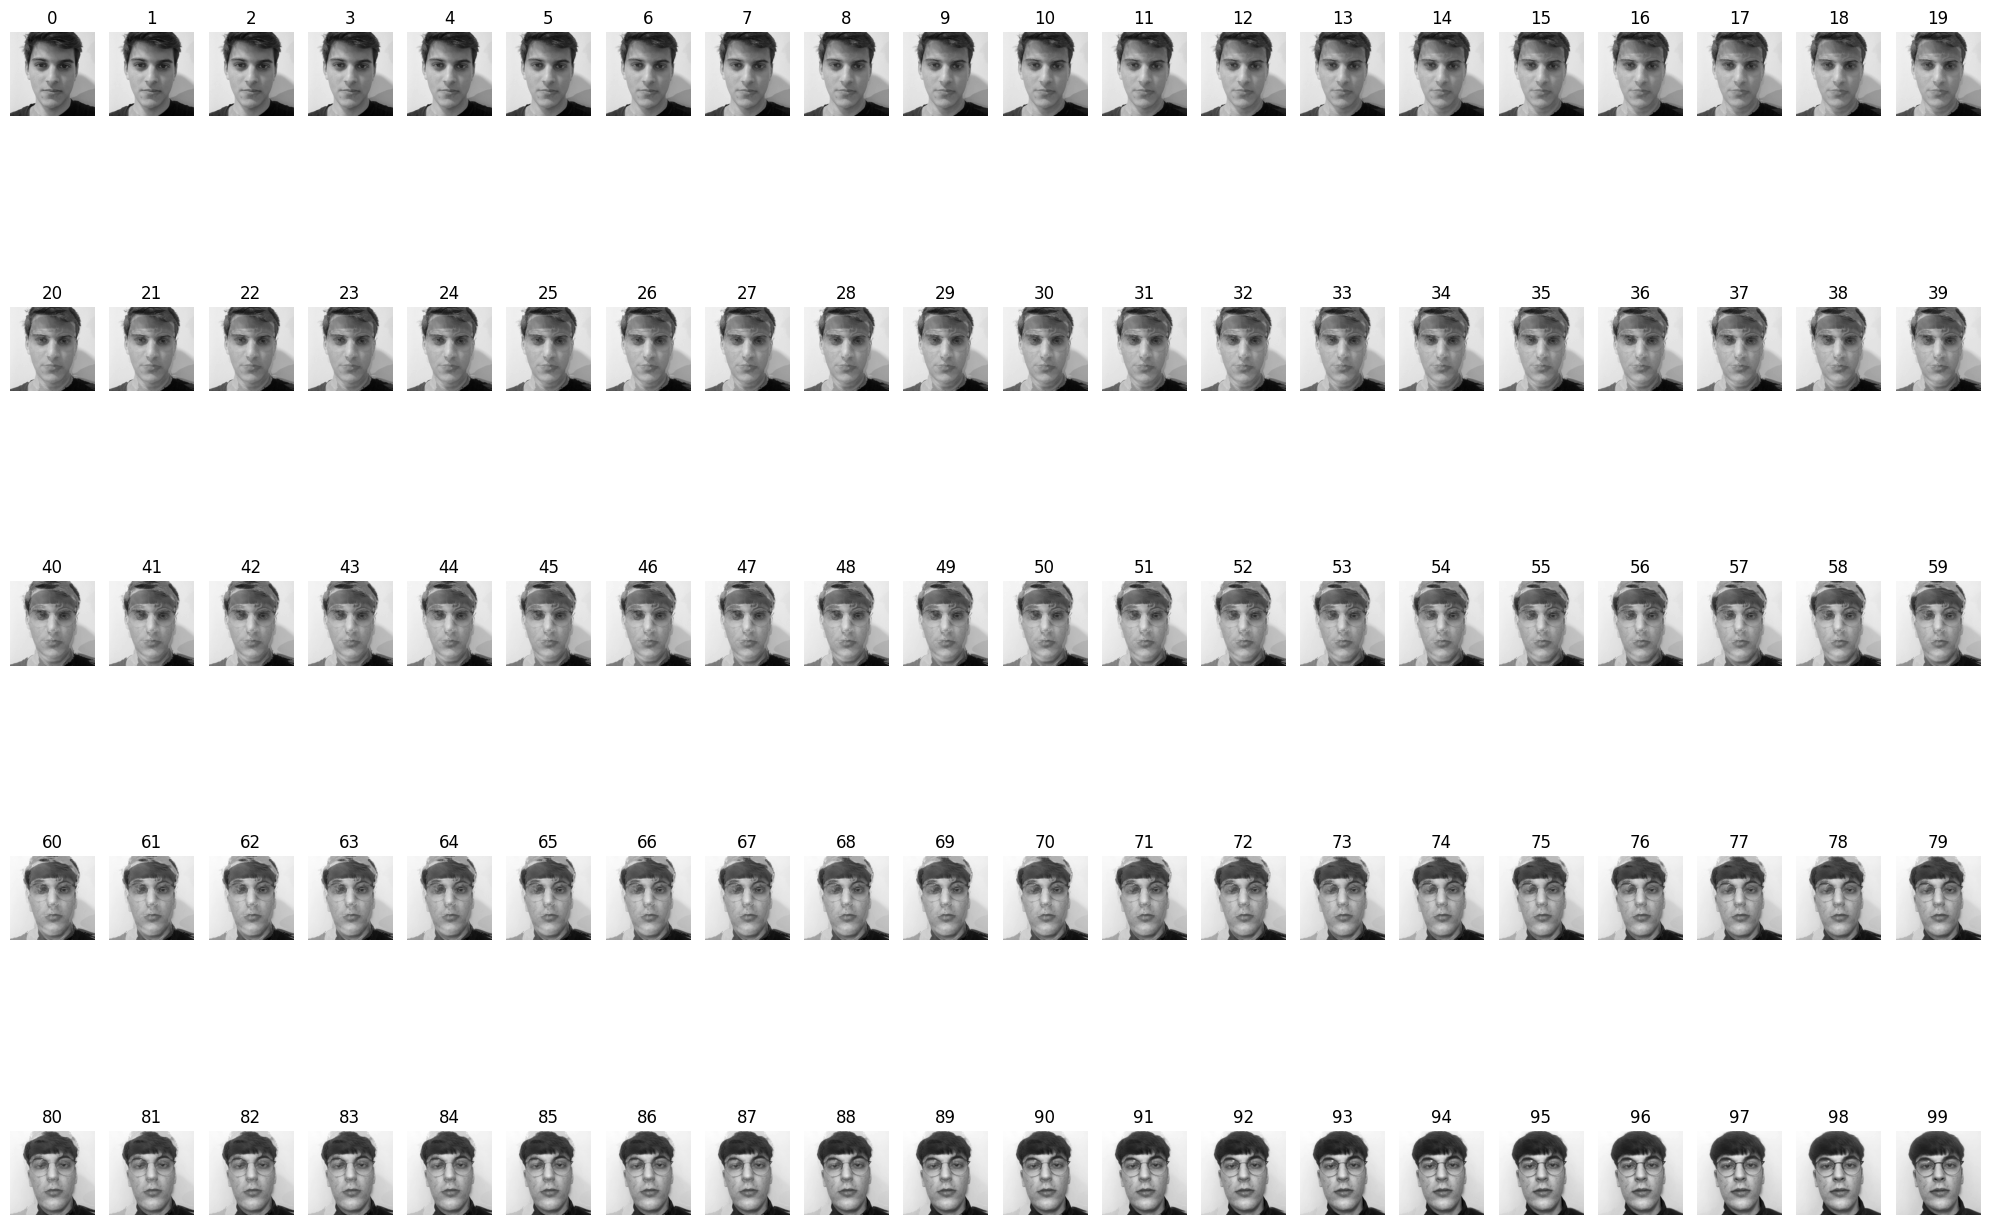

In [136]:
# Visualización de todos los frames en un grid
def show_frames_in_subplots(frames, group=10):
    n = len(frames)
    cols = group
    rows = (n + cols - 1) // cols
    plt.figure(figsize=(20, 3 * rows))
    for i, frame in enumerate(frames):
        plt.subplot(rows, cols, i + 1)
        plt.imshow(frame, cmap="gray")
        plt.axis("off")
        plt.title(f"{i}")
    plt.tight_layout()
    plt.show()

# Mostramos el grid completo
show_frames_in_subplots(frames, group=20)

In [ ]:
# Parametros
SIZE = 512
REG = 0.001       # Regularización normalizada
ITERS = 20        # Iteraciones de Sinkhorn
FRAMES = 700      # Número de cuadros en el GIF

# Rutas de las imágenes
path1 = "data/cara1.jpg"
path2 = "data/cara2.jpg"

print(f"Iniciando Morphing entre {path1} y {path2}...")

# Carga y peprocesamiento
img0_raw, mu0 = load_and_preprocess(path1, size=SIZE)
img1_raw, mu1 = load_and_preprocess(path2, size=SIZE)

# Cálculo de transporte óptimo
print(f"Resolviendo OT (Reg={REG}, Iters={ITERS})...")
reg_pixel = REG * (SIZE ** 2) # Escalamos epsilon por el tamaño en pixeles
u, v = sinkhorn_convolutional(mu0, mu1, reg_pixel, ITERS)

# Cálculo de vectores de desplazamiento
dx_fw, dy_fw = get_displacement_field(u, reg_pixel) # Forward (A -> B)
dx_bw, dy_bw = get_displacement_field(v, reg_pixel) # Backward (B -> A)

# Generación de frames
print(f"Generando {FRAMES} frames de interpolación...")
frames = generate_frames(img0_raw, img1_raw, dx_fw, dy_fw, dx_bw, dy_bw, n_frames=FRAMES)

# Guardamos el resultado
output_file = "data/morphing_final.gif"
imageio.mimsave(output_file, frames, fps=35)
print(f"\nMorphing guardado en: {output_file}")

Iniciando Morphing entre cara1.jpg y cara2.jpg...
Resolviendo OT (Reg=0.001, Iters=20)...
Generando 700 frames de interpolación...

Morphing guardado en: morphing_final.gif


In [138]:
# Imprimir las matrices numéricas de los frames
frames

[array([[230, 225, 228, ..., 210, 213, 208],
        [230, 230, 227, ..., 207, 208, 209],
        [230, 229, 233, ..., 205, 209, 212],
        ...,
        [ 59,  45,  49, ...,  12,   7,  20],
        [ 42,  49,  57, ...,  15,  18,  17],
        [ 55,  50,  56, ...,  22,  17,  17]], dtype=uint8),
 array([[229, 225, 227, ..., 210, 213, 208],
        [229, 229, 226, ..., 207, 208, 209],
        [229, 228, 232, ..., 205, 209, 212],
        ...,
        [ 59,  45,  49, ...,  12,   7,  19],
        [ 42,  49,  57, ...,  15,  17,  17],
        [ 55,  50,  56, ...,  22,  17,  17]], dtype=uint8),
 array([[229, 225, 227, ..., 210, 213, 208],
        [229, 229, 226, ..., 207, 208, 209],
        [229, 228, 232, ..., 205, 209, 212],
        ...,
        [ 59,  45,  49, ...,  12,   8,  18],
        [ 42,  49,  57, ...,  15,  17,  17],
        [ 55,  50,  56, ...,  22,  17,  17]], dtype=uint8),
 array([[229, 225, 227, ..., 210, 213, 208],
        [229, 229, 226, ..., 207, 208, 209],
        [229, 22

#### **Conclusiones:**
- En primer lugar, el morphing ha sido realizado en una escala de grises al ser esto más sencillo. Podría implementarse en color pero, a pesar de funcional, las texturas se pierden y se forma una amalgama de colores muy distorsionada en la que no se aprecia el morphing físicamente como en una escala de grises. Además, el coste sería triplicado (uno por gama de color de RGB).

- La segunda conclusión es acerca del ghosting que se está produciendo. En este caso, como las imágenes no están perfectamente alineadas, llega a producirse un ghosting en el que una cara solapa a la otra y viceversa. Es posible que lo pudiésemos mejorar añadiendo landmarks para que los píxeles de los ojos de la cara A fuesen a los de la cara B, la boca, etcétera, pero requeriría del uso de librerías externas de reconocimiento facial.

- Contraituitivamente, un mayor número de iteraciones empeora la calidad visual de los resultados. Cuando llevamos un gran numero de iteraciones, los valores de K son muy pequeños por estar usando un epsilon pequeños. Para compensar, los valores de escalado u y v tienden a infinito y a cero para equilibrar las ecuaciones. A partir de un punto, la precisión de float32 o 64 no es suficiente y muchos valores se redondean a 0 (underflow) o 1 (overflow), produciendo rayas blancas y negras. Con pocas iteraciones, se tiende a capturar la estructura global y con muchas se observa mucho ruido para cumplir estrictamente con las restricciones de cada píxel.

- Por último y como curiosidad, con este ejercicio se nos ha venido a la mente el videoclip de Black or White de Michael Jackson. En el último minuto de la canción en Youtube pueden verse muchos cambios de cara extremadamente fluidos. ¿Puede ser que estas transformaciones se realizasen con morphing y landmarks? 